# Classification Binaire

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

In [19]:
data = pd.read_csv('diabetes.csv')

data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [20]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**remaque** ici on constate qu il y a des valeurs manquantes, par ex le clucose, pression arterielle et epaisseur de la peau, insuline et BMI (rapport masse taille) ont des min à 0 chose qui est impossible.

**place au nettoyage de ces donnees en mettant ces 0 a null**

In [21]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
data[cols] = data[cols].replace(0, np.nan)
data.isna().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

### visualisation des donnees manquante sur tableau

<Axes: >

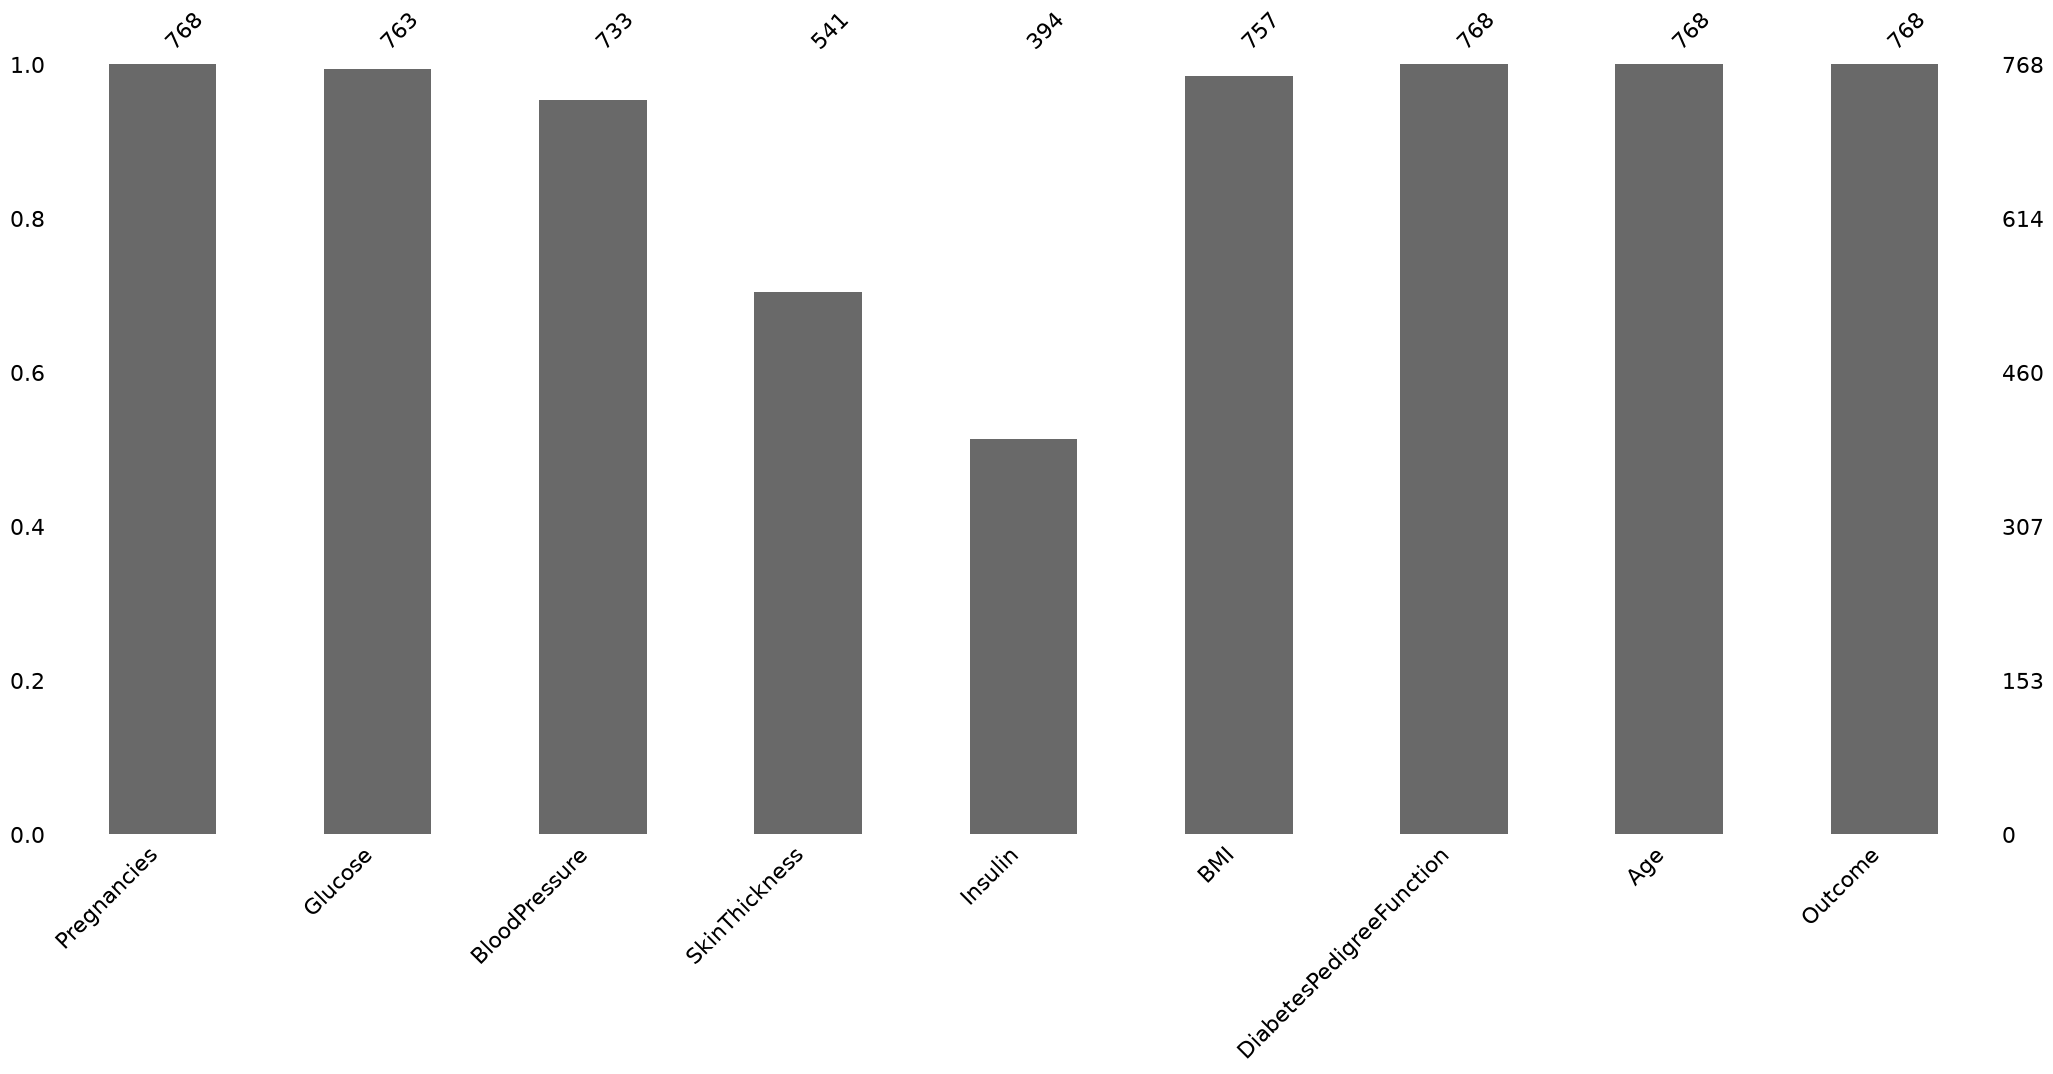

In [24]:
import missingno as msno

msno.bar(data)



In [27]:
data[cols] = data[cols].fillna(data[cols].median())
# data.isna().sum()

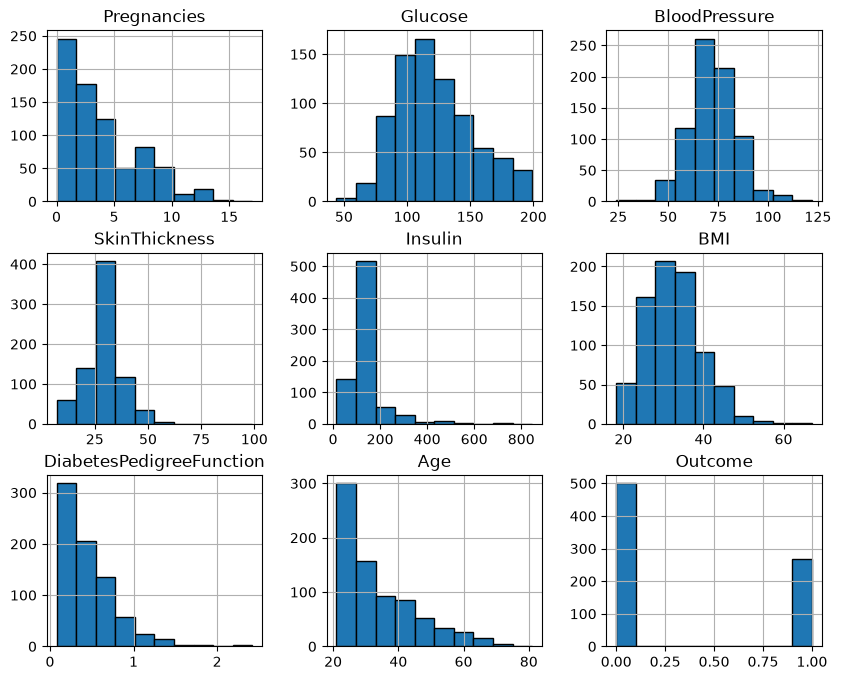

In [30]:
data.hist(figsize=(10, 8), edgecolor='black');

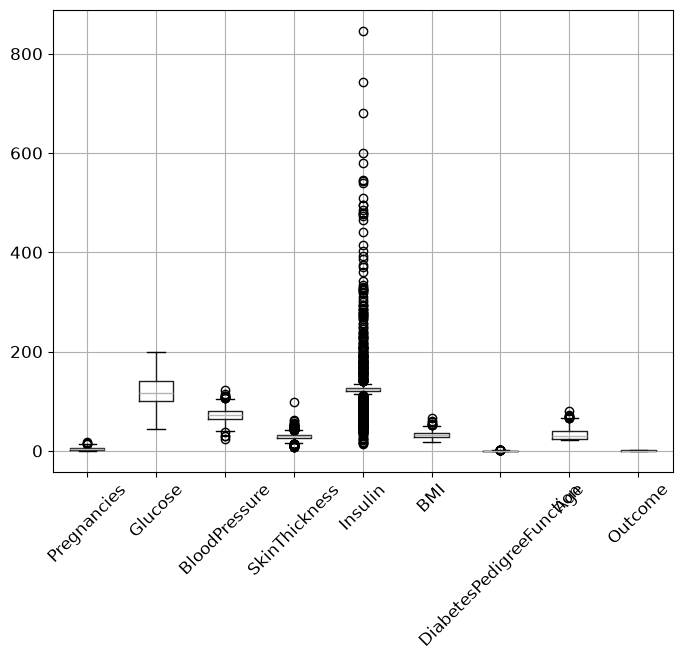

In [34]:
data.boxplot(figsize=(8, 6), rot=45, fontsize=12);
plt.show()

La on constate des **out layers** : donnees sortant des regroupements

### representation des variables par parts par rapport a l output (crosstab)

In [ ]:
for i in data.columns:
    if i != 'Outcome':
        (pd.crosstab(data[i], data['Outcome'], normalize='index')*100).plot(kind='bar', figsize=(8, 6), stacked=True, title=f'Percentage of Outcome by {i}')


<Axes: title={'center': 'Mean of Features by Outcome'}, xlabel='Outcome'>

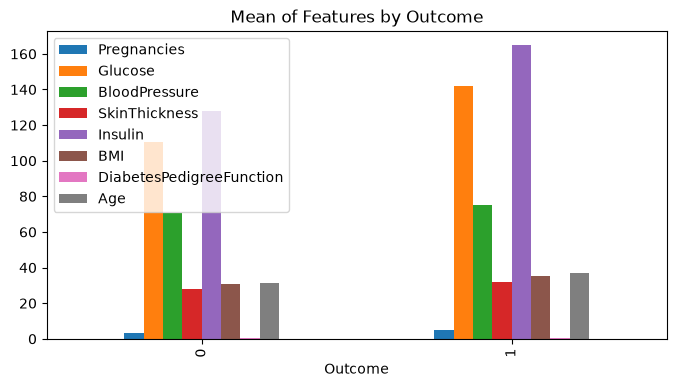

In [43]:
data.groupby('Outcome').mean().plot(kind='bar', figsize=(8, 4), title='Mean of Features by Outcome')